# <a id='toc1_'></a>[Title](#toc0_)
- Member 1
- Member 2
- Member 3

**Table of contents**<a id='toc0_'></a>    
  - [Import libraries and data](#toc1_1_)    
  - [Check NaNs, cast data types](#toc1_2_)    
  - [Part 1: Preprocessing the documents](#toc1_3_)    
  - [Part 2: EDA](#toc1_4_)    

<!-- vscode-jupyter-toc-config
	numbering=false
	anchor=true
	flat=false
	minLevel=1
	maxLevel=6
	/vscode-jupyter-toc-config -->
<!-- THIS CELL WILL BE REPLACED ON TOC UPDATE. DO NOT WRITE YOUR TEXT IN THIS CELL -->

## <a id='toc1_1_'></a>[Import libraries and data](#toc0_)

In [1]:
import pandas as pd
from nltk.stem import PorterStemmer
from nltk.tokenize import RegexpTokenizer
from nltk.corpus import stopwords
import nltk
nltk.download('stopwords')

[nltk_data] Downloading package stopwords to
[nltk_data]     C:\Users\34678\AppData\Roaming\nltk_data...
[nltk_data]   Package stopwords is already up-to-date!


True

In [2]:
# Read fashion products dataset
data_dir = "../../data/"
filename = "fashion_products_dataset.json"
df = pd.read_json(data_dir+filename)
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 28080 entries, 0 to 28079
Data columns (total 17 columns):
 #   Column           Non-Null Count  Dtype         
---  ------           --------------  -----         
 0   _id              28080 non-null  str           
 1   actual_price     28080 non-null  str           
 2   average_rating   28080 non-null  str           
 3   brand            28080 non-null  str           
 4   category         28080 non-null  str           
 5   crawled_at       28080 non-null  datetime64[ms]
 6   description      28080 non-null  str           
 7   discount         28080 non-null  str           
 8   images           28080 non-null  object        
 9   out_of_stock     28080 non-null  bool          
 10  pid              28080 non-null  str           
 11  product_details  28080 non-null  object        
 12  seller           28080 non-null  str           
 13  selling_price    28080 non-null  str           
 14  sub_category     28080 non-null  str           
 

## <a id='toc1_2_'></a>[Check NaNs, cast data types](#toc0_)

In [3]:
# Check for missing values, including empty and whitespace-only strings
print("Missing values, including empty and whitespace-only strings:")
display(
    df.replace(r"^\s*$", pd.NA, regex=True)
      .isna()
      .sum()
)

# Verify product identifiers are unique
assert df["pid"].notna().all()
assert df["pid"].is_unique

Missing values, including empty and whitespace-only strings:


_id                    0
actual_price         777
average_rating      2261
brand               2009
category               0
crawled_at             0
description        11150
discount             855
images                 0
out_of_stock           0
pid                    0
product_details        0
seller              1643
selling_price          2
sub_category           0
title                  0
url                    0
dtype: int64

Before proceeding, we convert all numeric columns from strings to float. The column `out_of_stock` is already boolean, so we keep it unchanged.

In [4]:
df_old = df.copy()

# Convert prices to numeric values:
# "2,999" -> 2999; missing or invalid values -> NaN
for column in ["actual_price", "selling_price"]:
    cleaned = (
        df_old[column]
        .astype("string")
        .str.replace(",", "", regex=False)
        .str.strip()
    )

    df[column] = pd.to_numeric(cleaned, errors="raise")

# Convert discounts to percentage points:
# "69% off" -> 0.69; missing or invalid values -> NaN
df["discount"] = pd.to_numeric(
    df_old["discount"]
    .astype("string")
    .str.extract(r"^\s*(\d+(?:\.\d+)?)\s*%\s*off\s*$", expand=False)
)/100

# Convert ratings to numeric values:
# "3.9" -> 3.9; missing or invalid values -> NaN
df["average_rating"] = pd.to_numeric(
    df_old["average_rating"].astype("string").str.strip(),
    errors="coerce"
)

# Show the dataframe with the new numeric columns
numeric_cols = ["actual_price", "selling_price", "discount", "average_rating"]
print("Before:")
display(df_old[numeric_cols].head(3))
print("After:")
display(df[numeric_cols].head(3))

# Verify new data types are Float64
print("Data types of numeric fields:")
display(df[numeric_cols].dtypes)

Before:


,actual_price,selling_price,discount,average_rating
0,"2,999",921,69% off,3.9
1,"1,499",499,66% off,3.9
2,"2,999",931,68% off,3.9


After:


,actual_price,selling_price,discount,average_rating
0,2999.0,921.0,0.69,3.9
1,1499.0,499.0,0.66,3.9
2,2999.0,931.0,0.68,3.9


Data types of numeric fields:


actual_price      Float64
selling_price     Float64
discount          Float64
average_rating    Float64
dtype: object

## <a id='toc1_3_'></a>[Part 1: Preprocessing the documents](#toc0_)

In this part we create two dataframes:

1. `df` has product information *without* preprocessing. For example, in the first row ‘description’ = ‘Wool Black pants made out of 100% cotton’.
2. `index_df` only contains the fields we’ll use in the index. All fields are pre-processed (lowercase, stemmed, etc.). For example, in the first row ‘description’ = [‘wool', 'black', 'pant', 'mad', '100', 'cotton’].

The first dataframe holds the information we'll later display in the search results: the product's title, description, etc. as it was originally written. The second will be used to create the index and to perform the exploratory data analysis (EDA). We are interested in keeping the fields separate in both cases so we give each field a different weight in the index.

In [5]:
# Preprocess the text of the description column
def build_terms(text):
    """
    Preprocess text removing stop words, stemming,
    transforming in lowercase and return the tokens of the text.

    :param text: to be preprocessed
    :returns: a list of tokens corresponding to the input text after the preprocessing
    """

    stemmer = PorterStemmer()
    tokenizer = RegexpTokenizer(r'\w+')             # keep only words & numbers, drop punctuation
    stop_words = set(stopwords.words("english"))
    text= text.lower()                              # transform in lowercase
    text=  tokenizer.tokenize(text)                 # tokenize the text to get a list of terms
    text=[t for t in text if t not in stop_words]   # eliminate the stopwords
    text=[stemmer.stem(t) for t in text]            # perform stemming
    return text

test_row = df.iloc[0]
print(f"Before: {test_row['description']}")
print(f"After: {build_terms(test_row['description'])}")

Before: Yorker trackpants made from 100% rich combed cotton giving it a rich look.Designed for Comfort,Skin friendly fabric,itch-free waistband & great for all year round use Proudly made in India
After: ['yorker', 'trackpant', 'made', '100', 'rich', 'comb', 'cotton', 'give', 'rich', 'look', 'design', 'comfort', 'skin', 'friendli', 'fabric', 'itch', 'free', 'waistband', 'great', 'year', 'round', 'use', 'proudli', 'made', 'india']


In [6]:
index_df = pd.DataFrame()
index_df['pid'] = df['pid']

index_cols = ["title", "description", "brand", "category", "sub_category", "seller"]
for col in index_cols:
    index_df[col] = df[col].apply(build_terms)
index_df.head(3)

,pid,title,description,brand,category,sub_category,seller
0,TKPFCZ9EA7H5FYZH,"[solid, women, multicolor, track, pant]","[yorker, trackpant, made, 100, rich, comb, cot...",[york],"[cloth, accessori]",[bottomwear],"[shyam, enterpris]"
1,TKPFCZ9EJZV2UVRZ,"[solid, men, blue, track, pant]","[yorker, trackpant, made, 100, rich, comb, cot...",[york],"[cloth, accessori]",[bottomwear],"[shyam, enterpris]"
2,TKPFCZ9EHFCY5Z4Y,"[solid, men, multicolor, track, pant]","[yorker, trackpant, made, 100, rich, comb, cot...",[york],"[cloth, accessori]",[bottomwear],"[shyam, enterpris]"


The column `product_details` also includes some information that might be useful for the index. The problem is it is structured as a dictionary. Also, we don't want to include the dictionary keys, they'd simply add noise to our terms.

In [7]:
test_row.product_details

[{'Style Code': '1005COMBO2'},
 {'Closure': 'Elastic'},
 {'Pockets': 'Side Pockets'},
 {'Fabric': 'Cotton Blend'},
 {'Pattern': 'Solid'},
 {'Color': 'Multicolor'}]

Therefore, we get the values of the dictionary, extract the terms and add them to our `index_df`.

In [8]:
def values_to_string(details):
    """
    Convert a product's details into a single string of its values.

    :param details: list of single-entry dicts, e.g. [{'Closure': 'Elastic'}, {'Color': 'Multicolor'}]
    :returns: a string with all the detail values joined by spaces (e.g. 'Elastic Multicolor'),
              or NaN if the input is not a list
    """
    if not isinstance(details, list):
        return pd.NA
    return " ".join(str(v) for d in details for v in d.values())

In [9]:
# Preprocess (lowercase, stem, etc.) and add to our index info 
index_df['product_details'] = df['product_details'].apply(values_to_string).apply(build_terms)
index_df.head(3)

,pid,title,description,brand,category,sub_category,seller,product_details
0,TKPFCZ9EA7H5FYZH,"[solid, women, multicolor, track, pant]","[yorker, trackpant, made, 100, rich, comb, cot...",[york],"[cloth, accessori]",[bottomwear],"[shyam, enterpris]","[1005combo2, elast, side, pocket, cotton, blen..."
1,TKPFCZ9EJZV2UVRZ,"[solid, men, blue, track, pant]","[yorker, trackpant, made, 100, rich, comb, cot...",[york],"[cloth, accessori]",[bottomwear],"[shyam, enterpris]","[1005blue, drawstr, elast, side, pocket, cotto..."
2,TKPFCZ9EHFCY5Z4Y,"[solid, men, multicolor, track, pant]","[yorker, trackpant, made, 100, rich, comb, cot...",[york],"[cloth, accessori]",[bottomwear],"[shyam, enterpris]","[1005combo4, elast, side, pocket, cotton, blen..."


In [10]:
df.to_csv(data_dir + f"fashion_products.csv", index=False)
index_df.to_csv(data_dir + f"index_info.csv", index=False)
print(f"✅ Saved 2 files to {data_dir}")

✅ Saved 2 files to ../../data/


## <a id='toc1_4_'></a>[Part 2: EDA](#toc0_)

**List of features prone to be analyzed**
* Missing rate on each field statistics --> We need to process the missing values
* Are the categories balanced? --> Explore top and low categories
* Distribution of length of title, description, final tokens
* Most common words --> This can be used for TF
* Distribution of price, ratings, discount
* Top sellers and brands regarding product quantities
* Stok

### Category distribution

Count products using the original category names in `df`. The first plot compares all categories; the next two show the most and least frequent subcategories. These plots describe the dataset composition without changing it.


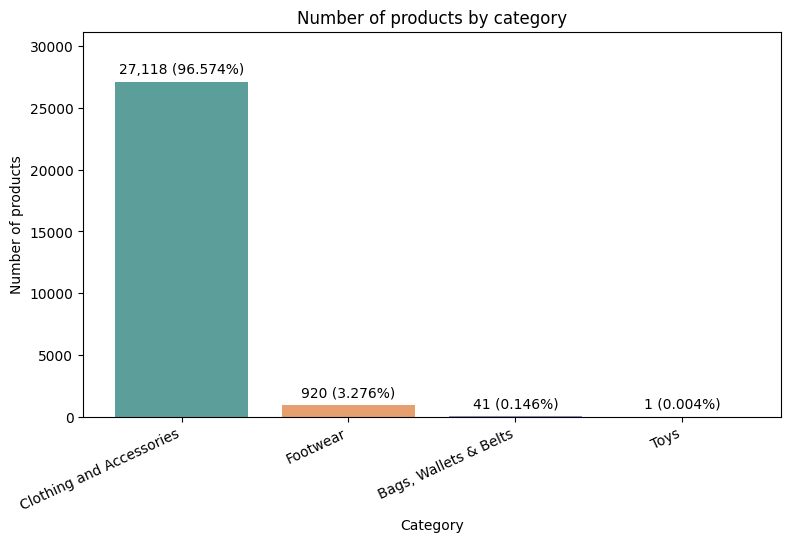

In [ ]:
import matplotlib.pyplot as plt

# Each row is one product because pid is unique.
category_counts = df["category"].value_counts()

plt.figure(figsize=(9, 5))
bars = plt.bar(category_counts.index, category_counts.values,
               color=["#5B9E9A", "#E6A06F", "#9B8CB9", "#D7BA65"])
plt.bar_label(
    bars,
    labels=[f"{n:,} ({n / len(df):.3%})" for n in category_counts.values],
    padding=4
)
plt.ylim(0, category_counts.max() * 1.15)
plt.title("Number of products by category")
plt.xlabel("Category")
plt.ylabel("Number of products")
plt.xticks(rotation=25, ha="right")
# plt.tight_layout()
plt.show()


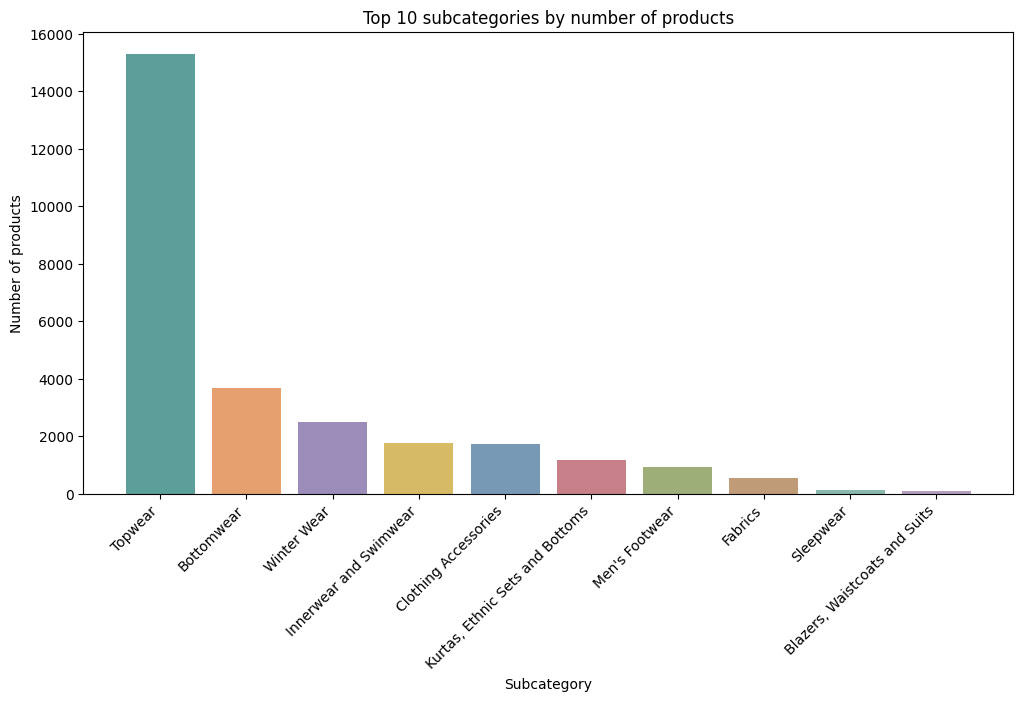

In [ ]:
subcategory_counts = df["sub_category"].value_counts()
top_subcategories = subcategory_counts.head(10)

plt.figure(figsize=(12, 6))
subcategory_palette = ["#5B9E9A", "#E6A06F", "#9B8CB9", "#D7BA65",
                       "#7899B5", "#C88088", "#9DAE78", "#BF9B78",
                       "#89B8AD", "#B49DC1"]
subcategory_colors = {name: subcategory_palette[i % len(subcategory_palette)]
                      for i, name in enumerate(subcategory_counts.index)}
plt.bar(top_subcategories.index, top_subcategories.values,
        color=[subcategory_colors[name] for name in top_subcategories.index])
plt.title("Top 10 subcategories by number of products")
plt.xlabel("Subcategory")
plt.ylabel("Number of products")
plt.xticks(rotation=45, ha="right")
# plt.tight_layout()
plt.show()


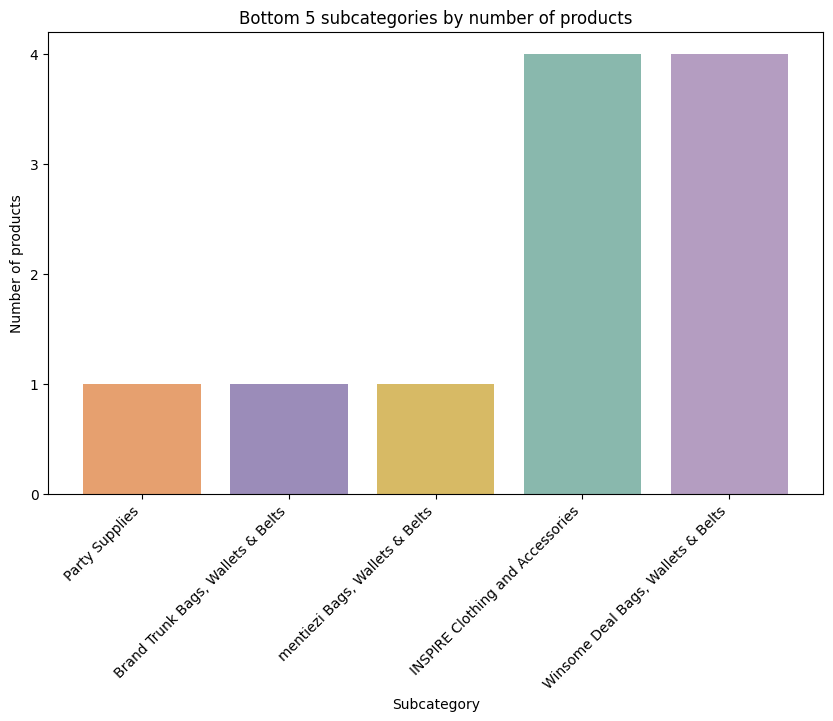

In [ ]:
# Select five of the least frequent subcategories; counts may be tied.
bottom_subcategories = subcategory_counts.nsmallest(5)

plt.figure(figsize=(10, 6))
plt.bar(bottom_subcategories.index, bottom_subcategories.values,
        color=[subcategory_colors[name] for name in bottom_subcategories.index])
plt.title("Bottom 5 subcategories by number of products")
plt.xlabel("Subcategory")
plt.ylabel("Number of products")
plt.yticks(range(int(bottom_subcategories.max()) + 1))
plt.xticks(rotation=45, ha="right")
# plt.tight_layout()
plt.show()


Compare the dominant category with the others, then inspect the concentration in the largest subcategories. The Bottom 5 plot shows five of the smallest groups; ties mean that other groups can have the same counts.


### Price distributions

Use the cleaned numeric prices in `df`. Exclude missing values separately for
each price field, retaining the other product records. Titles show valid sample
sizes and medians. Both panels use the same price range for comparison; no
currency is assumed because its unit has not been verified.


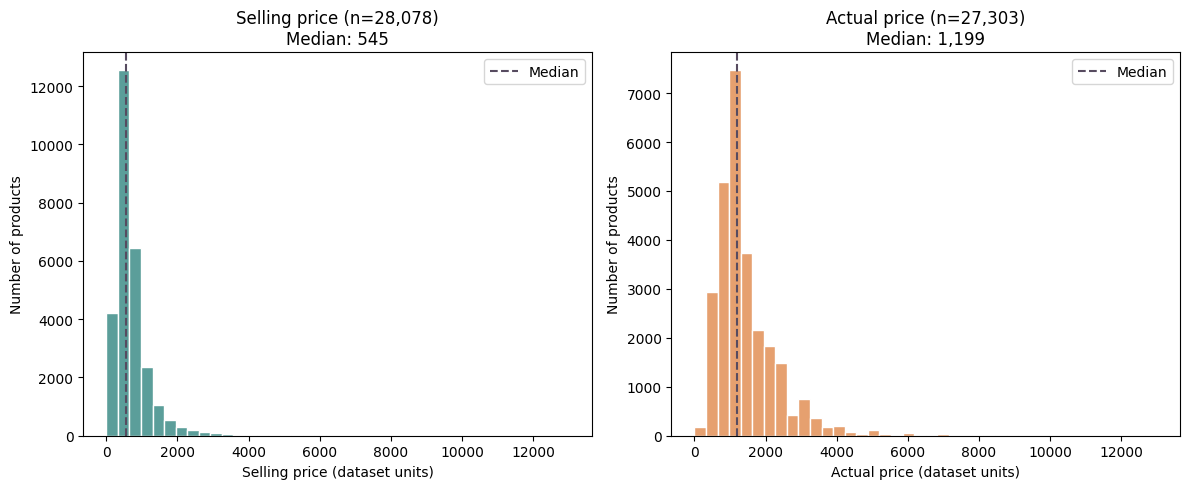

In [ ]:
selling_prices = df["selling_price"].dropna()
actual_prices = df["actual_price"].dropna()
price_limit = max(selling_prices.max(), actual_prices.max())

plt.figure(figsize=(12, 5))
plt.subplot(1, 2, 1)
plt.hist(selling_prices.astype(float), bins=40, range=(0, price_limit), color="#5B9E9A", edgecolor="white")
plt.axvline(selling_prices.median(), color="#574B60", linestyle="--", label="Median")
plt.title(f"Selling price (n={len(selling_prices):,})\nMedian: {selling_prices.median():,.0f}")
plt.xlabel("Selling price (dataset units)")
plt.ylabel("Number of products")
plt.legend()

plt.subplot(1, 2, 2)
plt.hist(actual_prices.astype(float), bins=40, range=(0, price_limit), color="#E6A06F", edgecolor="white")
plt.axvline(actual_prices.median(), color="#574B60", linestyle="--", label="Median")
plt.title(f"Actual price (n={len(actual_prices):,})\nMedian: {actual_prices.median():,.0f}")
plt.xlabel("Actual price (dataset units)")
plt.ylabel("Number of products")
plt.legend()
plt.tight_layout()
plt.show()


### Rating and discount distributions

Missing ratings and discounts are excluded separately, not filled with zero or
the mean. The cleaned discount is a proportion, so multiply by 100 for plotting
percentage values. All valid values are retained.


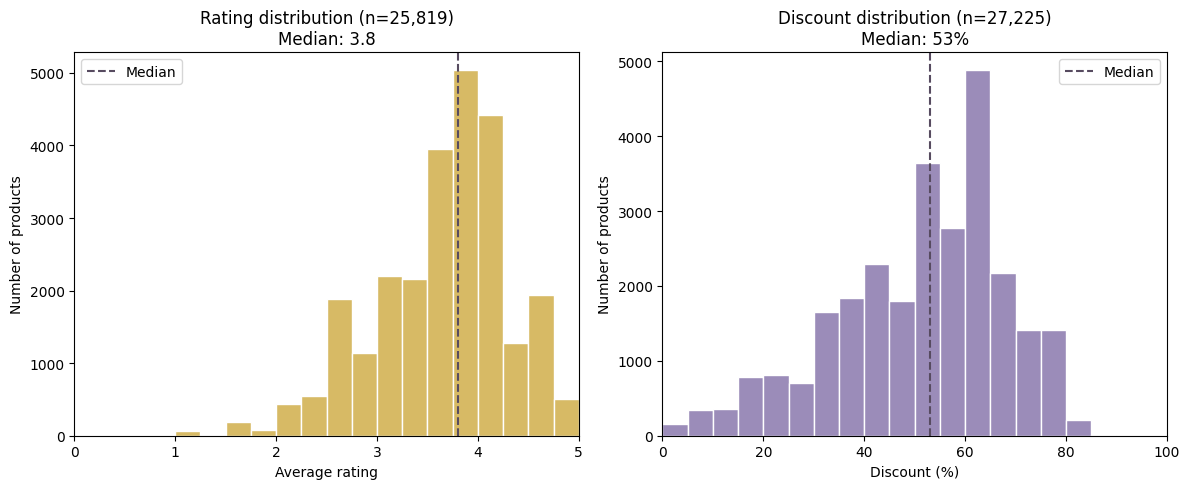

In [ ]:
ratings = df["average_rating"].dropna()
discounts = df["discount"].dropna() * 100

plt.figure(figsize=(12, 5))
plt.subplot(1, 2, 1)
plt.hist(ratings.astype(float), bins=20, range=(0, 5), color="#D7BA65", edgecolor="white")
plt.axvline(ratings.median(), color="#574B60", linestyle="--", label="Median")
plt.title(f"Rating distribution (n={len(ratings):,})\nMedian: {ratings.median():.1f}")
plt.xlabel("Average rating")
plt.ylabel("Number of products")
plt.xlim(0, 5)
plt.legend()

plt.subplot(1, 2, 2)
plt.hist(discounts.astype(float), bins=20, range=(0, 100), color="#9B8CB9", edgecolor="white")
plt.axvline(discounts.median(), color="#574B60", linestyle="--", label="Median")
plt.title(f"Discount distribution (n={len(discounts):,})\nMedian: {discounts.median():.0f}%")
plt.xlabel("Discount (%)")
plt.ylabel("Number of products")
plt.xlim(0, 100)
plt.legend()
plt.tight_layout()
plt.show()


### Top brands and sellers by product quantity

Count product records, not sales. Exclude missing or blank names, trim whitespace,
and group case-insensitively while preserving a readable name for display.
These temporary Series do not change the original names in `df`.


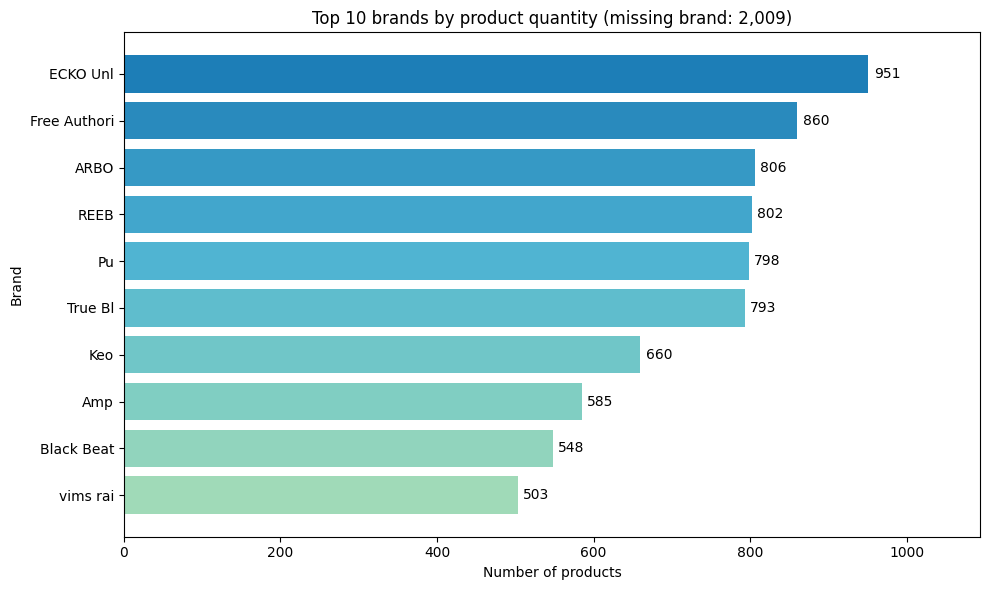

In [ ]:
brand_names = df["brand"].astype("string").str.strip().replace("", pd.NA)
brand_keys = brand_names.str.casefold()
brand_counts = brand_keys.value_counts().head(10)
brand_labels = brand_names.groupby(brand_keys).first().reindex(brand_counts.index)

plt.figure(figsize=(10, 6))
bars = plt.barh(brand_labels, brand_counts.values,
                color=plt.cm.GnBu([0.8 - i * 0.045 for i in range(len(brand_counts))]))
plt.gca().invert_yaxis()
plt.bar_label(bars, padding=4)
plt.xlim(0, brand_counts.max() * 1.15)
plt.title(f"Top 10 brands by product quantity (missing brand: {brand_names.isna().sum():,})")
plt.xlabel("Number of products")
plt.ylabel("Brand")
plt.tight_layout()
plt.show()


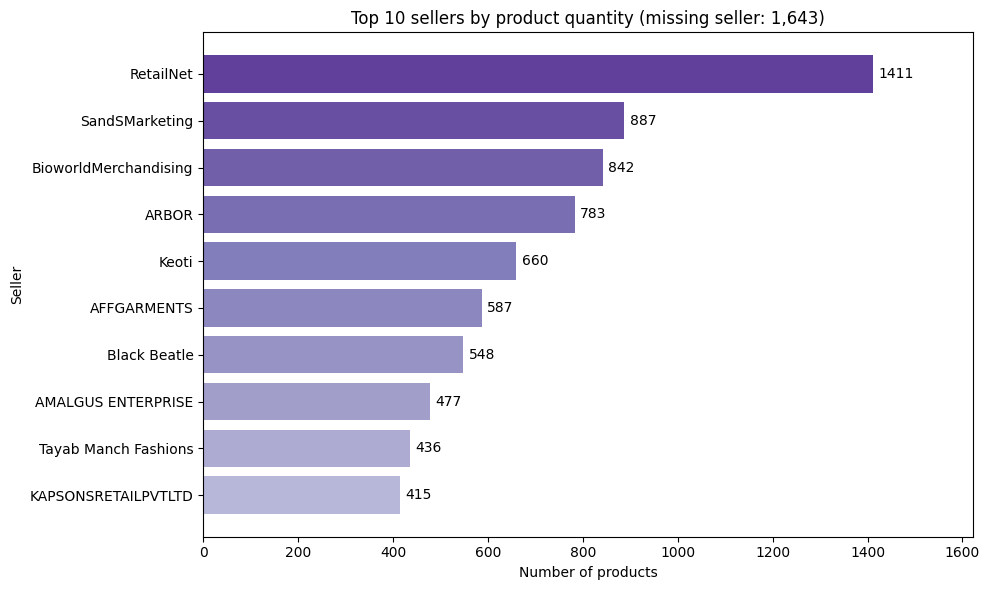

In [ ]:
seller_names = df["seller"].astype("string").str.strip().replace("", pd.NA)
seller_keys = seller_names.str.casefold()
seller_counts = seller_keys.value_counts().head(10)
seller_labels = seller_names.groupby(seller_keys).first().reindex(seller_counts.index)

plt.figure(figsize=(10, 6))
bars = plt.barh(seller_labels, seller_counts.values,
                color=plt.cm.Purples([0.8 - i * 0.045 for i in range(len(seller_counts))]))
plt.gca().invert_yaxis()
plt.bar_label(bars, padding=4)
plt.xlim(0, seller_counts.max() * 1.15)
plt.title(f"Top 10 sellers by product quantity (missing seller: {seller_names.isna().sum():,})")
plt.xlabel("Number of products")
plt.ylabel("Seller")
plt.tight_layout()
plt.show()


### Stock availability

`out_of_stock=False` means in stock; `True` means out of stock. Percentages use
products with a known stock status. This describes availability at collection
time, not changes in stock over time.


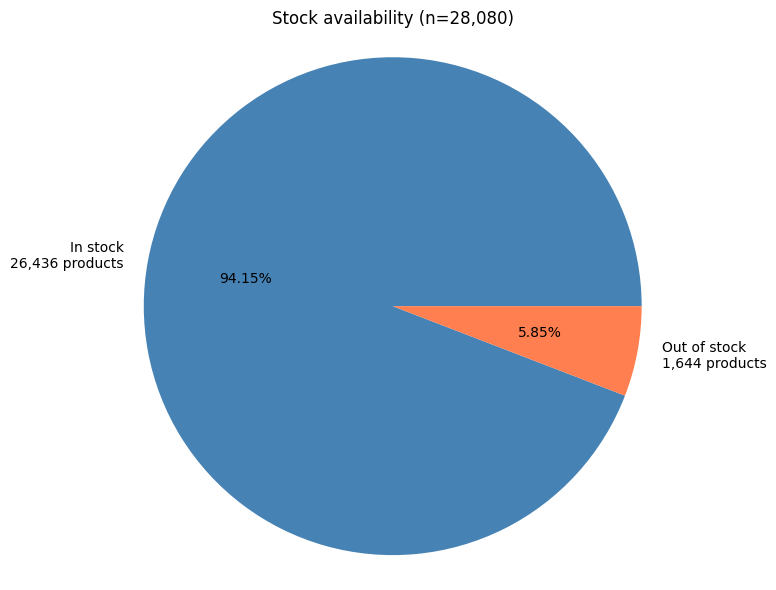

In [ ]:
stock = df["out_of_stock"].dropna()
stock_counts = [stock.eq(False).sum(), stock.eq(True).sum()]

plt.figure(figsize=(7, 6))
plt.pie(
    stock_counts,
    labels=[f"In stock\n{stock_counts[0]:,} products",
            f"Out of stock\n{stock_counts[1]:,} products"],
    autopct="%1.2f%%",
    startangle=0,
    colors=["steelblue", "coral"]
)
plt.title(f"Stock availability (n={len(stock):,})")
plt.axis("equal")
plt.tight_layout()
plt.show()
